# Proyecto Integrador – Fase 2: Preprocesamiento, Ingeniería de Variables y Modelo Base

**Dataset:** *Hotel Booking Demand* (Kaggle, `jessemostipak/hotel-booking-demand`)

| | |
|---|---|
| **Asignatura** | Ciencia de Datos — Maestría en Inteligencia Artificial |
| **Institución** | Universidad de La Salle |
| **Integrantes** | Miguel Angel Ricardo · Jose Alexander Barahona Calderon |
| **Docente** | Fabián Camilo Castro Riveros |
| **Entregable** | Entregable 2 — Fase 2 (Actividades 3 y 4) |
| **Fecha de entrega** | 15 de noviembre de 2026 |

Este cuaderno continúa el trabajo de la Fase 1 (planteamiento del problema y EDA) y aplica sus recomendaciones. Es **ejecutable de principio a fin** en Google Colab.

**Principio rector:** toda transformación que *aprende* de los datos (cuantiles, medias, encoders, escaladores) se ajusta **únicamente con el conjunto de entrenamiento**, para evitar *data leakage*.

**Contenido**

| Bloque | Contenido |
|---|---|
| 1 | Carga y reglas de calidad determinísticas |
| 2 | Tratamiento de valores faltantes (mecanismo MCAR/MAR/MNAR) |
| 3 | Incoherencias y valores inválidos |
| 4 | Duplicados |
| 5 | Ingeniería de variables y control de fuga de información |
| 6 | Partición de datos (estratificada, agrupada y temporal) |
| 7 | Valores atípicos (ajustados solo en entrenamiento) |
| 8 | Preprocesador sin fuga de datos (encoding y escalado) |
| 9 | Desbalance de clases |
| 10 | Modelos base (baseline) |
| 11 | Verificación final y reproducibilidad |# Sección nueva

## 0. Preparación del entorno

### 0.1 Instalación de librerías
Se instala `kagglehub` (descarga de datasets públicos **sin token**) e `imbalanced-learn` (técnicas de remuestreo como SMOTE). *scikit-learn*, pandas, NumPy, SciPy y Matplotlib ya vienen instalados en Colab. Las versiones exactas utilizadas se registran en la sección 11 para generar `requirements.txt`.

In [ ]:
!pip install -q kagglehub imbalanced-learn

### 0.2 Importación de librerías, semilla y estilo gráfico
Se heredan de la Fase 1 la semilla única `SEED = 42` y la guía de estilo de las figuras (paleta apta para daltonismo: **azul = no cancelada**, **naranja = cancelada**, **violeta = City Hotel**, **aqua = Resort Hotel**), para que ambas fases sean coherentes.

In [ ]:
import os
import datetime
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from cycler import cycler
import scipy
from scipy import stats
from IPython.display import display

import sklearn
import imblearn
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, mean_squared_error, mean_absolute_error, r2_score,
    confusion_matrix, precision_recall_curve, auc
)
from sklearn.base import BaseEstimator, TransformerMixin

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# --- Paleta (heredada de la Fase 1) ---
AZUL, NARANJA, AQUA, VIOLETA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100"
GRIS, GRIS_CLARO, GRIS_CUADRICULA = "#8a8985", "#c9c7c1", "#e6e5e1"
TINTA, TINTA_2 = "#1f1f1e", "#52514e"
COLOR_ESTADO = {"No cancelada": AZUL, "Cancelada": NARANJA}
COLOR_HOTEL = {"City Hotel": VIOLETA, "Resort Hotel": AQUA}

plt.rcParams.update({
    "figure.figsize": (11, 5), "figure.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRIS, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRIS_CUADRICULA, "grid.linewidth": 0.8,
    "axes.labelcolor": TINTA_2, "axes.labelsize": 10.5,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "font.size": 10.5, "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": cycler(color=[AZUL, NARANJA, AQUA, AMARILLO, VIOLETA]),
})

FUENTE = "Fuente: Hotel Booking Demand (Antonio, Almeida y Nunes, 2019) — Kaggle"

def titular(ax, titulo, subtitulo=None):
    ax.set_title(titulo, loc="left", fontsize=13, fontweight="bold", color=TINTA,
                 pad=24 if subtitulo else 10)
    if subtitulo:
        ax.text(0, 1.025, subtitulo, transform=ax.transAxes, fontsize=10,
                color=TINTA_2, va="bottom", ha="left")

def citar_fuente(fig, texto=FUENTE, y=-0.03):
    fig.text(0.01, y, texto, fontsize=8.5, color=GRIS, ha="left")

SEED = 42
DIR_FIGURAS = "figures_fase2"
os.makedirs(DIR_FIGURAS, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(os.path.join(DIR_FIGURAS, f"{nombre}.png"), dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__)

pandas 2.2.3 | numpy 2.4.6 | scipy 1.16.3 | matplotlib 3.10.0
scikit-learn 1.6.1 | imbalanced-learn 0.14.2


### 0.3 Descarga del dataset desde Kaggle (sin token)
Se descarga la **versión 1** del dataset público con `kagglehub`, la misma de la Fase 1, para garantizar reproducibilidad. Si Kaggle no estuviera disponible, se usa el espejo público de *TidyTuesday*. `df_raw` se conserva **sin modificar** durante todo el cuaderno.

In [ ]:
import kagglehub

DATASET = "jessemostipak/hotel-booking-demand"
VERSION = 1
URL_RESPALDO = ("https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
                "master/data/2020/2020-02-11/hotels.csv")

try:
    ruta = kagglehub.dataset_download(f"{DATASET}/versions/{VERSION}")
    RUTA_CSV = os.path.join(ruta, "hotel_bookings.csv")
    ORIGEN = "Kaggle (kagglehub, sin token)"
except Exception as e:
    print("No fue posible descargar desde Kaggle:", e)
    RUTA_CSV = "hotel_bookings.csv"
    urllib.request.urlretrieve(URL_RESPALDO, RUTA_CSV)
    ORIGEN = "Espejo público TidyTuesday"

df_raw = pd.read_csv(RUTA_CSV)
FECHA_EXTRACCION = datetime.date.today()
TAMANO_MB = os.path.getsize(RUTA_CSV) / 1e6

print(f"Origen: {ORIGEN} | Fecha de extracción: {FECHA_EXTRACCION:%Y-%m-%d} | Tamaño: {TAMANO_MB:.2f} MB")
print(f"Registros: {df_raw.shape[0]:,} | Variables: {df_raw.shape[1]}")
print(f"Tasa de cancelación (archivo crudo): {df_raw['is_canceled'].mean():.2%}")

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Origen: Kaggle (kagglehub, sin token) | Fecha de extracción: 2026-11-09 | Tamaño: 16.86 MB
Registros: 119,390 | Variables: 32
Tasa de cancelación (archivo crudo): 37.04%


## 1. Carga y reglas de calidad determinísticas

Se parte de `df_raw` (archivo original sin modificar). Se aplican únicamente reglas **lógicas** que no dependen de la distribución de los datos y, por lo tanto, no pueden producir fuga de información:

| Regla | Justificación |
|---|---|
| Eliminar reservas sin huéspedes (adultos + niños + bebés = 0) | Una reserva sin personas no representa una estancia real |
| Eliminar ADR negativo o mayor a 1,000 € | Valores imposibles o de captura errónea (hallazgo de la Fase 1) |
| Unificar `meal` = "Undefined" con "SC" | Según el diccionario del dataset, ambas significan "sin plan de comidas" |

Antes de cualquier transformación se calcula una **llave de grupo** (`grupo_dup`): un *hash* de las 32 columnas originales. Las filas idénticas comparten la misma llave, lo que permitirá mantener copias idénticas **siempre en el mismo conjunto** (entrenamiento, validación o prueba) en el Bloque 6 y evitar que una copia en entrenamiento "revele" a su gemela en prueba.# Sección nueva

In [ ]:
# 1) Llave de grupo para duplicados exactos: se calcula sobre las 32 columnas ORIGINALES
df2 = df_raw.copy()
df2["id_original"] = df2.index                                   # trazabilidad
df2["grupo_dup"] = pd.util.hash_pandas_object(df_raw, index=False).values

# 2) Reglas determinísticas
children_tmp = df2["children"].fillna(0)                          # solo para evaluar la regla
sin_huespedes = (df2["adults"] + children_tmp + df2["babies"]) == 0
adr_invalido  = (df2["adr"] < 0) | (df2["adr"] > 1000)
meal_undef    = df2["meal"] == "Undefined"

reglas = pd.DataFrame({
    "Regla": ["Reservas sin huéspedes", "ADR negativo o > 1,000 €", "meal 'Undefined' → 'SC' (recodificadas)"],
    "Registros afectados": [int(sin_huespedes.sum()), int(adr_invalido.sum()), int(meal_undef.sum())],
    "Acción": ["Eliminar", "Eliminar", "Recodificar"],
})
display(reglas)

df2["meal"] = df2["meal"].replace("Undefined", "SC")
df2 = df2[~sin_huespedes & ~adr_invalido].reset_index(drop=True)

# 3) Verificación frente a la Fase 1
n_antes, n_despues = len(df_raw), len(df2)
print(f"\nRegistros originales: {n_antes:,} | tras reglas: {n_despues:,} | eliminados: {n_antes - n_despues:,}")
print(f"Coincide con la Fase 1 (119,208): {n_despues == 119_208}")

# 4) Vista de la llave de duplicados
tam_grupo = df2.groupby("grupo_dup")["grupo_dup"].transform("size")
print(f"\nGrupos distintos de filas: {df2['grupo_dup'].nunique():,}")
print(f"Filas que pertenecen a un grupo con copias: {(tam_grupo > 1).sum():,} ({(tam_grupo > 1).mean():.1%})")
print(f"Tamaño máximo de un grupo: {tam_grupo.max()}")
print(f"\nTasa de cancelación tras las reglas: {df2['is_canceled'].mean():.2%}")

,Regla,Registros afectados,Acción
0,Reservas sin huéspedes,180,Eliminar
1,"ADR negativo o > 1,000 €",2,Eliminar
2,meal 'Undefined' → 'SC' (recodificadas),1169,Recodificar



Registros originales: 119,390 | tras reglas: 119,208 | eliminados: 182
Coincide con la Fase 1 (119,208): True

Grupos distintos de filas: 87,228
Filas que pertenecen a un grupo con copias: 40,141 (33.7%)
Tamaño máximo de un grupo: 180

Tasa de cancelación tras las reglas: 37.08%


### 1.1 Resultados de las reglas determinísticas

| Regla | Registros afectados | Acción |
|---|---|---|
| Reservas sin huéspedes | 180 | Eliminar |
| ADR negativo o > 1,000 € | 2 | Eliminar |
| `meal` = "Undefined" → "SC" | 1,169 | Recodificar |

Se eliminaron **182 registros (0.15 %)** y quedaron **119,208 reservas**, cifra idéntica a la de la Fase 1. La tasa de cancelación pasó de 37.04 % a 37.08 %, de modo que las reglas no alteraron la distribución de la variable objetivo.

### 1.2 Llave de grupo de duplicados

Las 119,208 filas forman **87,228 grupos distintos**. El **33.7 %** de las filas (40,141) pertenece a un grupo con copias exactas y el grupo más grande tiene **180 filas idénticas**. Esto confirma que los duplicados no son casos aislados: son bloques de reservas repetidas. Si copias idénticas quedaran repartidas entre entrenamiento y prueba, el modelo se evaluaría sobre registros que ya vio y las métricas saldrían infladas. Por eso, en el Bloque 6, la partición se hará **por grupos** usando `grupo_dup`.

## 2. Tratamiento de valores faltantes

### 2.1 Diagnóstico y mecanismo de falta

Un faltante es **MCAR** si su ausencia no depende de nada, **MAR** si depende de otras variables observadas y **MNAR** si depende del propio valor no observado. Para distinguirlos se compara, entre registros **con y sin dato**, la tasa de cancelación y la proporción del Resort Hotel, y se aplica una prueba χ² de independencia entre "tener nulo" y `is_canceled`. Si los registros con nulo se comportan distinto, el faltante **no es MCAR** y no debe imputarse a ciegas.

In [ ]:
# --- Diagnóstico de nulos sobre df2 (datos tras las reglas del Bloque 1) ---
nulos = df2.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
resumen = pd.DataFrame({"n_nulos": nulos, "pct_nulos": nulos / len(df2) * 100})
display(resumen.style.format({"n_nulos": "{:,}", "pct_nulos": "{:.3f} %"}))

# --- Mecanismo: ¿los registros con nulo se comportan distinto? ---
filas = []
for col in resumen.index:
    nulo = df2[col].isna()
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(nulo, df2["is_canceled"]))
    filas.append({
        "variable": col,
        "n_nulos": int(nulo.sum()),
        "cancel_con_nulo_%": df2.loc[nulo, "is_canceled"].mean() * 100,
        "cancel_con_dato_%": df2.loc[~nulo, "is_canceled"].mean() * 100,
        "%_Resort_con_nulo": (df2.loc[nulo, "hotel"] == "Resort Hotel").mean() * 100,
        "%_Resort_con_dato": (df2.loc[~nulo, "hotel"] == "Resort Hotel").mean() * 100,
        "p_valor_χ²": p,
    })
mecanismo = pd.DataFrame(filas).set_index("variable")
display(mecanismo.style.format({"n_nulos": "{:,}", "p_valor_χ²": "{:.2e}"}, precision=1))

print("Canal de distribución de las reservas SIN agente (%):")
print((df2.loc[df2["agent"].isna(), "distribution_channel"].value_counts(normalize=True) * 100).round(1).to_string())

,n_nulos,pct_nulos
company,"112,440",94.323 %
agent,"16,280",13.657 %
country,478,0.401 %
children,4,0.003 %


,n_nulos,cancel_con_nulo_%,cancel_con_dato_%,%_Resort_con_nulo,%_Resort_con_dato,p_valor_χ²
variable,,,,,,
company,"112,440",38.3,17.4,32.9,45.8,1.97e-259
agent,"16,280",24.7,39.0,50.4,30.9,1.06e-272
country,478,11.9,37.2,96.7,33.3,6.60e-30
children,4,100.0,37.1,0.0,33.6,3.68e-02


Canal de distribución de las reservas SIN agente (%):
distribution_channel
Direct      46.70
Corporate   33.90
TA/TO       19.40
Undefined    0.00
GDS          0.00


### 2.2 Decisión de tratamiento

Con base en el mecanismo identificado, el tratamiento es el siguiente. Todas las imputaciones usan **constantes** o **indicadores de ausencia**, que no se calculan a partir de los datos; por lo tanto son seguras antes de la partición y no generan fuga de información.

In [ ]:
# --- Aplicación del tratamiento ---
# company: estructural (no hay empresa pagadora) → indicador + eliminar el código de alta cardinalidad
df2["tiene_empresa"] = df2["company"].notna().astype(int)
df2 = df2.drop(columns=["company"])

# agent: MAR (reserva que no pasó por agencia) → indicador + categoría propia "0" como variable nominal de tipo str
df2["tiene_agente"] = df2["agent"].notna().astype(int)
df2["agent"] = df2["agent"].fillna(0).astype(int).astype(str)

# country: MAR (95 % del Resort) → categoría propia "Desconocido"
df2["country"] = df2["country"].fillna("Desconocido")

# children: MAR/MNAR (4 casos aislados, asumido MAR por comportamiento de segmentación) → 0
df2["children"] = df2["children"].fillna(0).astype(int)

# --- Tabla de decisiones y verificación ---
decisiones = pd.DataFrame({
    "Variable": ["company", "agent", "country", "children"],
    "Mecanismo": ["Estructural (cercano a MNAR)", "MAR", "MAR", "MAR (Asumido)"],
    "Tratamiento": ["Indicador tiene_empresa y eliminar código",
                    "Indicador tiene_agente + categoría nominal '0'",
                    "Categoría 'Desconocido'",
                    "Imputar 0"],
    "¿Aprende de los datos?": ["No", "No", "No", "No"],
})
display(decisiones)

print(f"Nulos restantes en df2: {int(df2.isna().sum().sum())}")
print(f"Dimensiones de df2: {df2.shape[0]:,} filas × {df2.shape[1]} columnas")
print("Reservas con agente:", f"{df2['tiene_agente'].mean():.1%}", "| con empresa:", f"{df2['tiene_empresa'].mean():.1%}")

,Variable,Mecanismo,Tratamiento,¿Aprende de los datos?
0,company,Estructural (cercano a MNAR),Indicador tiene_empresa y eliminar código,No
1,agent,MAR,Indicador tiene_agente + categoría nominal '0',No
2,country,MAR,Categoría 'Desconocido',No
3,children,MAR (Asumido),Imputar 0,No


Nulos restantes en df2: 0
Dimensiones de df2: 119,208 filas × 35 columnas
Reservas con agente: 86.3% | con empresa: 5.7%


### 2.3 Resultados del diagnóstico de faltantes

Sobre las 119,208 reservas válidas, solo 4 variables tienen faltantes:

| Variable | Nulos | % | Cancelación con nulo | Cancelación con dato | % Resort con nulo | % Resort con dato | p (χ²) |
|---|---|---|---|---|---|---|---|
| `company` | 112,440 | 94.32 % | 38.3 % | 17.4 % | 32.9 % | 45.8 % | 1.97e-259 |
| `agent` | 16,280 | 13.66 % | 24.7 % | 39.0 % | 50.4 % | 30.9 % | 1.06e-272 |
| `country` | 478 | 0.40 % | 11.9 % | 37.2 % | 96.7 % | 33.3 % | 6.60e-30 |
| `children` | 4 | 0.003 % | 100 % | 37.1 % | 0.0 % | 33.6 % | 3.68e-02 (*) |

(*) Con n = 4 las frecuencias esperadas son menores que 5, por lo que la prueba χ² no es concluyente.

**Interpretación.** Con más de 119 mil registros, cualquier diferencia pequeña resulta estadísticamente significativa, por lo que se prioriza el **tamaño de la diferencia**:

* **`company` (estructural, cercano a MNAR):** el nulo significa "no hay empresa pagadora". Las reservas sin empresa cancelan 38.3 % frente a 17.4 % con empresa. La ausencia es información en sí misma, así que se conserva como indicador `tiene_empresa` y se elimina el código (alta cardinalidad, 94 % vacío).
* **`agent` (MAR):** las reservas sin agente se concentran en los canales *Direct* (46.7 %) y *Corporate* (33.9 %) y cancelan menos (24.7 % frente a 39.0 %). El nulo indica que la reserva **no pasó por una agencia**, por lo que se codifica como categoría propia (0) y se conserva el indicador `tiene_agente`.
* **`country` (MAR):** el 96.7 % de los nulos pertenece al Resort Hotel y cancelan solo 11.9 %. La falta depende del hotel (probablemente de su sistema de registro), por lo que se usa la categoría "Desconocido".
* **`children` (indeterminado, n = 4):** no es posible determinar el mecanismo con tan pocos casos. Se imputa 0 (la moda) porque su impacto es despreciable.

**Ninguno de los faltantes relevantes es MCAR**, por lo que una imputación por media o mediana sería inapropiada. Todos los tratamientos usan **constantes o indicadores** que no se calculan a partir de los datos, de modo que son seguros antes de la partición y no generan fuga de información.

### 2.4 Resultado del tratamiento

Tras la imputación quedan **0 valores nulos** y el DataFrame tiene **119,208 filas × 35 columnas**. El 86.3 % de las reservas tiene agente y el 5.7 % tiene empresa.

## 3. Incoherencias y valores inválidos

La Fase 1 dejó pendientes varios casos marcados como "revisar". Antes de decidir su tratamiento se **diagnostica su comportamiento** (tasa de cancelación, ADR y segmento), porque eliminar registros solo se justifica si son errores y no reservas reales atípicas.# Sección nueva

In [ ]:
noches  = df2["stays_in_weekend_nights"] + df2["stays_in_week_nights"]
menores = df2["children"] + df2["babies"]

reglas3 = {
    "ADR = 0":                            df2["adr"] == 0,
    "ADR = 0 y segmento ≠ Complementary": (df2["adr"] == 0) & (df2["market_segment"] != "Complementary"),
    "Estancia de 0 noches":               noches == 0,
    "Estancia de 0 noches y ADR = 0":     (noches == 0) & (df2["adr"] == 0),
    "Menores sin adulto":                 (df2["adults"] == 0) & (menores > 0),
    "Adultos > 10":                       df2["adults"] > 10,
    "Bebés ≥ 9":                          df2["babies"] >= 9,
    "Niños ≥ 10":                         df2["children"] >= 10,
}
tabla3 = pd.DataFrame([{
    "Regla": k, "Registros": int(m.sum()), "% del total": m.mean() * 100,
    "Cancelación %": df2.loc[m, "is_canceled"].mean() * 100 if m.any() else np.nan,
    "ADR mediano": df2.loc[m, "adr"].median() if m.any() else np.nan,
} for k, m in reglas3.items()])
display(tabla3.round(2))

# --- Detalle: ADR = 0 ---
m0 = reglas3["ADR = 0"]
print("\nADR = 0: segmento × cancelación")
print(pd.crosstab(df2.loc[m0, "market_segment"], df2.loc[m0, "is_canceled"], margins=True).to_string())

# --- Detalle: 0 noches ---
mz = reglas3["Estancia de 0 noches"]
print("\n0 noches: hotel × estado final")
print(pd.crosstab(df2.loc[mz, "hotel"], df2.loc[mz, "reservation_status"], margins=True).to_string())
print("ADR máximo en 0 noches:", df2.loc[mz, "adr"].max())

# --- Detalle: menores sin adulto ---
mm = reglas3["Menores sin adulto"]
print("\nMenores sin adulto:", int(mm.sum()))
print(pd.crosstab(df2.loc[mm, "hotel"], df2.loc[mm, "reservation_status"], margins=True).to_string())
print(df2.loc[mm, "market_segment"].value_counts().to_string())

# --- Detalle: huéspedes extremos ---
ext = reglas3["Adultos > 10"] | reglas3["Bebés ≥ 9"] | reglas3["Niños ≥ 10"]
print(f"\nHuéspedes extremos: {int(ext.sum())}")
print(df2.loc[ext].groupby(["hotel", "arrival_date_year", "arrival_date_month"]).size().to_string())
display(df2.loc[ext, ["hotel", "adults", "children", "babies", "market_segment",
                      "adr", "lead_time", "is_canceled"]])

print("\nUndefined en market_segment:", int((df2["market_segment"] == "Undefined").sum()),
      "| en distribution_channel:", int((df2["distribution_channel"] == "Undefined").sum()))

# --- Aplicación de las decisiones ---
n0, t0 = len(df2), df2["is_canceled"].mean() * 100
df2 = df2[~ext].reset_index(drop=True)                      # elimina los 15 extremos
df2["apto_regresion"] = (df2["adr"] > 0).astype(int)        # regla lógica: sin fuga
print(f"\nEliminados {int(ext.sum())}: {n0:,} → {len(df2):,} registros | "
      f"cancelación {t0:.2f} % → {df2['is_canceled'].mean() * 100:.2f} %")
print(f"Aptos para regresión (adr > 0): {int(df2['apto_regresion'].sum()):,} "
      f"({df2['apto_regresion'].mean():.1%})")

decisiones3 = pd.DataFrame([
    ("ADR = 0 (1,810)", "Estancias reales sin ingreso: 89.6 % hace check-out y cancela 10.4 %",
     "Conservar en clasificación; excluir de regresión (apto_regresion = 0)"),
    ("0 noches (645)", "Todas tienen ADR = 0; 96.4 % check-out; cancelan 3.6 %",
     "Conservar en clasificación; excluir de regresión; prop_fin_semana = 0"),
    ("Menores sin adulto (223)", "Todas City Hotel (84 % Online TA); cancelan 37.7 % y ADR mediano 88.8 €: se comportan como reservas normales",
     "Conservar"),
    ("Huéspedes extremos (15)", "12 con >10 adultos: Resort, sep-oct 2015, ADR = 0, 100 % canceladas; 2 con ≥9 bebés y 1 con 10 niños",
     "Eliminar (errores de captura / marcadores de posición)"),
    ("Undefined (2 y 5)", "Categorías casi vacías", "Agrupar en 'Otros' en el Bloque 8"),
], columns=["Regla", "Evidencia", "Decisión"])
display(decisiones3)

,Regla,Registros,% del total,Cancelación %,ADR mediano
0,ADR = 0,1810,1.52,10.39,0.00
1,ADR = 0 y segmento ≠ Complementary,1145,0.96,9.08,0.00
2,Estancia de 0 noches,645,0.54,3.57,0.00
3,Estancia de 0 noches y ADR = 0,645,0.54,3.57,0.00
4,Menores sin adulto,223,0.19,37.67,88.77
5,Adultos > 10,12,0.01,100.00,0.00
6,Bebés ≥ 9,2,0.00,0.00,89.72
7,Niños ≥ 10,1,0.00,100.00,133.16



ADR = 0: segmento × cancelación
is_canceled        0    1   All
market_segment                 
Aviation           3    1     4
Complementary    581   84   665
Corporate         67    4    71
Direct           190   31   221
Groups           212   21   233
Offline TA/TO    266   31   297
Online TA        303   16   319
All             1622  188  1810

0 noches: hotel × estado final
reservation_status  Canceled  Check-Out  No-Show  All
hotel                                                
City Hotel                 6        251        7  264
Resort Hotel               4        371        6  381
All                       10        622       13  645
ADR máximo en 0 noches: 0.0

Menores sin adulto: 223
reservation_status  Canceled  Check-Out  No-Show  All
hotel                                                
City Hotel                81        139        3  223
All                       81        139        3  223
market_segment
Online TA        187
Direct            29
Complementary      

,hotel,adults,children,babies,market_segment,adr,lead_time,is_canceled
328,Resort Hotel,2,10,0,Offline TA/TO,133.16,55,1
1539,Resort Hotel,40,0,0,Direct,0.00,304,1
1587,Resort Hotel,26,0,0,Offline TA/TO,0.00,333,1
1643,Resort Hotel,50,0,0,Direct,0.00,336,1
1752,Resort Hotel,26,0,0,Offline TA/TO,0.00,340,1
1884,Resort Hotel,26,0,0,Offline TA/TO,0.00,347,1
1917,Resort Hotel,27,0,0,Direct,0.00,349,1
1962,Resort Hotel,27,0,0,Direct,0.00,352,1
2003,Resort Hotel,26,0,0,Offline TA/TO,0.00,354,1
2164,Resort Hotel,26,0,0,Offline TA/TO,0.00,361,1



Undefined en market_segment: 2 | en distribution_channel: 5

Eliminados 15: 119,208 → 119,193 registros | cancelación 37.08 % → 37.07 %
Aptos para regresión (adr > 0): 117,395 (98.5%)


,Regla,Evidencia,Decisión
0,"ADR = 0 (1,810)",Estancias reales sin ingreso: 89.6 % hace chec...,Conservar en clasificación; excluir de regresi...
1,0 noches (645),Todas tienen ADR = 0; 96.4 % check-out; cancel...,Conservar en clasificación; excluir de regresi...
2,Menores sin adulto (223),Todas City Hotel (84 % Online TA); cancelan 37...,Conservar
3,Huéspedes extremos (15),"12 con >10 adultos: Resort, sep-oct 2015, ADR ...",Eliminar (errores de captura / marcadores de p...
4,Undefined (2 y 5),Categorías casi vacías,Agrupar en 'Otros' en el Bloque 8


### 3.1 Interpretación de Incoherencias y Valores Inválidos

Para evitar eliminar datos que podrían corresponder a reservas reales, aunque atípicas, se analizaron los casos críticos mediante su tasa de cancelación y comportamiento operativo:

- **ADR = 0 y estancias de 0 noches:** Se identificó que la gran mayoría (89.6 % y 96.4 %, respectivamente) terminaron en Check-Out exitoso. Esto indica que son estancias reales (posiblemente cortesías o errores de registro de tarifa) y no errores de datos.
  - **Decisión:** Se conservan para el problema de clasificación, pero se crea la variable `apto_regresion` para excluirlos del problema de regresión, ya que un ADR de 0 sesgaría la predicción de ingresos.

- **Menores sin adultos:** Se detectó que el 100 % de estos casos pertenecen al City Hotel y su tasa de cancelación (37.7 %) y ADR mediano (88.8 €) son consistentes con el resto del dataset.
  - **Decisión:** Se conservan, ya que se comportan como reservas normales.

- **Huéspedes extremos:** Se hallaron 15 registros con valores irreales (ej. hasta 55 adultos en una sola reserva). La mayoría están concentrados en el Resort Hotel en fechas específicas de 2015, con ADR = 0 y 100 % de cancelación.
  - **Decisión:** Se eliminan por ser errores evidentes de captura o marcadores de posición (*placeholders*).

- **Categorías "Undefined":** Se encontraron casos aislados en `market_segment` (2) y `distribution_channel` (5).
  - **Decisión:** Debido a su irrelevancia estadística, se agruparán en una categoría "Otros" durante la etapa de *encoding* (Bloque 8).

**Resultado final:** Se eliminaron 15 registros, resultando en un conjunto de 119,193 reservas. Se estableció que el 98.5 % (117,395) de los datos son aptos para el análisis de regresión.

## 4. Análisis de Duplicados

En la Fase 1 se detectó un volumen considerable de filas idénticas. En lugar de eliminarlas indiscriminadamente, se analiza si estos duplicados representan un sesgo en la variable objetivo (`is_canceled`) o si son simplemente repeticiones administrativas.

La estrategia es fundamental para evitar la fuga de datos (*data leakage*): si una reserva tiene una copia exacta y una queda en el conjunto de entrenamiento mientras la otra queda en el de prueba, el modelo simplemente "recordará" el resultado en lugar de aprender a predecirlo, inflando artificialmente las métricas de rendimiento.

Por ello, se utiliza la llave `grupo_dup`, creada en el Bloque 1, para garantizar que todas las copias de un mismo registro permanezcan siempre en el mismo conjunto durante la partición.# Sección nueva

In [ ]:
# 1. Identificar filas duplicadas exactas
# Usamos las columnas originales para evitar que el 'id_original' o 'grupo_dup' interfieran
cols_originales = [c for c in df2.columns if c not in ["id_original", "grupo_dup", "apto_regresion"]]
dups_mask = df2.duplicated(subset=cols_originales, keep=False)
n_dups = dups_mask.sum()

# 2. Análisis de impacto en la variable objetivo (is_canceled)
tasa_global = df2["is_canceled"].mean()
tasa_dups = df2.loc[dups_mask, "is_canceled"].mean()
tasa_unicos = df2.loc[~dups_mask, "is_canceled"].mean()

# 3. Resumen de impacto
resumen_dups = pd.DataFrame({
    "Métrica": [
        "Total Registros",
        "Registros Duplicados",
        "% de Duplicados",
        "Tasa Cancelación Global",
        "Tasa Cancelación (Solo Duplicados)",
        "Tasa Cancelación (Solo Únicos)"
    ],
    "Valor": [
        f"{len(df2):,}",
        f"{n_dups:,}",
        f"{(n_dups/len(df2)):.2%}",
        f"{tasa_global:.2%}",
        f"{tasa_dups:.2%}",
        f"{tasa_unicos:.2%}"
    ]
})

display(resumen_dups)

# Verificación de la llave de grupo (para asegurar que la partición sea segura)
print(f"\nVerificación: Grupos de duplicados identificados: {df2['grupo_dup'].nunique():,}")

,Métrica,Valor
0,Total Registros,"119,193"
1,Registros Duplicados,"40,147"
2,% de Duplicados,33.68%
3,Tasa Cancelación Global,37.07%
4,Tasa Cancelación (Solo Duplicados),58.38%
5,Tasa Cancelación (Solo Únicos),26.25%



Verificación: Grupos de duplicados identificados: 87,213


### 4.1 Conclusiones del Análisis de Duplicados y Estrategia de Partición

El análisis revela un comportamiento sumamente interesante y crítico para el diseño del modelo:

* **Volumen significativo:** Un tercio del dataset original (**33.68 %**) está compuesto por filas que tienen al menos una copia idéntica.
* **Fuerte sesgo operativo:** La tasa de cancelación de las reservas duplicadas es del **58.38 %**, más del doble que la de las reservas únicas (**26.25 %**). Eliminar estos duplicados de manera indiscriminada alteraría de forma artificial la tasa global de cancelaciones y subestimaría el riesgo real de cancelación de reservas idénticas.
* **Decisión metodológica:** **No se eliminarán los duplicados.** Dado que son registros reales que reflejan una realidad del negocio (por ejemplo, reservas grupales masivas), eliminarlos sesgaría el modelo.
* **Prevención de Data Leakage:** Para evitar que el modelo "memorice" las etiquetas debido a la presencia de registros idénticos en entrenamiento y prueba, utilizaremos una **partición agrupada** en el Bloque 6 utilizando la variable de control `grupo_dup` como identificador de grupo.


## 5. Ingeniería de Variables y Control de Fuga

En esta etapa, transformamos los datos brutos en características que faciliten el aprendizaje del modelo. Nos enfocaremos en dos frentes:

1. **Creación de Variables Derivadas:** Basándonos en el conocimiento del dominio hotelero, crearemos nuevas variables que capturen mejor la realidad (por ejemplo, el total de personas en la reserva o la proporción de noches que caen en fin de semana). Estas variables ayudan al modelo a encontrar patrones que no son evidentes en las columnas individuales.

2. **Definición de Conjuntos de Variables por Problema:** Dado que el proyecto requiere resolver un problema de Clasificación (¿cancelará?) y uno de Regresión (¿cuál será el ADR?), no podemos usar las mismas variables. Definiremos una lista estricta para cada caso, eliminando cualquier variable que cause fuga de información (*data leakage*); es decir, variables que contienen información del futuro o que son consecuencias directas del evento que queremos predecir (como el estado final de la reserva).

In [ ]:
# 1. Creación de Variables Derivadas (Sentido de Dominio)
# total_huespedes: Capacidad total de la reserva
df2["total_huespedes"] = df2["adults"] + df2["children"] + df2["babies"]

# con_ninos: Indicador binario de presencia de menores (cambia la dinámica de viaje)
df2["con_ninos"] = (df2["children"] + df2["babies"] > 0).astype(int)

# total_noches: Duración total de la estancia
df2["total_noches"] = df2["stays_in_weekend_nights"] + df2["stays_in_week_nights"]

# prop_fin_semana: Proporción de la estancia que ocurre en fin de semana
# Usamos np.where para evitar división por cero en estancias de 0 noches
df2["prop_fin_semana"] = np.where(
    df2["total_noches"] > 0,
    df2["stays_in_weekend_nights"] / df2["total_noches"],
    0
)

# 2. Definición de Variables por Problema y Control de Leakage

# --- A. Problema de CLASIFICACIÓN (Target: is_canceled) ---
# Excluimos variables que son consecuencia de la cancelación (Leakage)
exclusiones_clasif = [
    "is_canceled",           # Target
    "reservation_status",    # Leakage: es el resultado final
    "reservation_status_date",# Leakage: fecha del resultado final
    "id_original", "grupo_dup", "apto_regresion" # Variables de control
]

# Seleccionamos todas las demás
vars_clasif = [c for c in df2.columns if c not in exclusiones_clasif]

# --- B. Problema de REGRESIÓN (Target: adr) ---
# Excluimos variables que son consecuencia o el target mismo
exclusiones_regresion = [
    "adr",                   # Target
    "is_canceled",            # Podría haber fuga si el ADR cambia según cancelación
    "reservation_status",    # Leakage
    "reservation_status_date",# Leakage
    "id_original", "grupo_dup", "apto_regresion" # Variables de control
]

vars_regresion = [c for c in df2.columns if c not in exclusiones_regresion]

# 3. Resumen de la Ingeniería
resumen_vars = pd.DataFrame({
    "Problema": ["Clasificación", "Regresión"],
    "Nº Variables": [len(vars_clasif), len(vars_regresion)],
    "Target": ["is_canceled", "adr"],
    "Principales Exclusiones (Leakage)": [
        "reservation_status, status_date",
        "adr, reservation_status"
    ]
})

display(resumen_vars)

print("\nVariables derivadas creadas:")
print("- total_huespedes: suma de adultos, niños y bebés")
print("- con_ninos: indicador de presencia de menores")
print("- total_noches: suma de noches semana y fin de semana")
print("- prop_fin_semana: ratio de noches fin de semana / total")

print(f"\nDimensiones finales de df2: {df2.shape}")

,Problema,Nº Variables,Target,Principales Exclusiones (Leakage)
0,Clasificación,34,is_canceled,"reservation_status, status_date"
1,Regresión,33,adr,"adr, reservation_status"



Variables derivadas creadas:
- total_huespedes: suma de adultos, niños y bebés
- con_ninos: indicador de presencia de menores
- total_noches: suma de noches semana y fin de semana
- prop_fin_semana: ratio de noches fin de semana / total

Dimensiones finales de df2: (119193, 40)


### 5.1 Justificación de las Características Creadas y Control de Fuga

1. **`total_huespedes`:** Combina adultos, niños y bebés para representar la ocupación total real de la habitación, una característica clave que afecta tanto a la probabilidad de cancelación como al costo (`adr`).
2. **`con_ninos`:** Identifica si hay menores en la reserva. Las dinámicas de viaje familiares difieren significativamente de las de negocios o parejas individuales.
3. **`total_noches`:** Suma de noches en días de semana y fines de semana, representando la longitud de la estadía.
4. **`prop_fin_semana`:** Proporción de noches de fin de semana sobre el total. Permite caracterizar si la reserva tiene un perfil vacacional o corporativo.

**Control Estricto de Fuga de Información (*Data Leakage*):**
Para el problema de **Clasificación**, la variable `reservation_status` y su fecha se excluyen por completo porque representan el desenlace del evento (Check-out o Cancelación). Para el problema de **Regresión**, se excluye la variable objetivo `adr`, además de `is_canceled` y el estado operativo final.

## 6. Estrategia de Partición de Datos y Prevención de Leakage

La partición de los datos es el paso más crítico para garantizar la validez de los resultados. Para evitar que el modelo optimice sus métricas artificialmente y asegurar que sea robusto en el tiempo, implementamos una estrategia de tres capas:

1. **Partición Agrupada (Grouped Split):** Como detectamos que el 33.68 % de los datos son duplicados exactos, no podemos usar una partición aleatoria simple. Utilizaremos la variable `grupo_dup` para asegurar que todas las copias de un mismo registro permanezcan estrictamente en el mismo conjunto (entrenamiento, validación o prueba). Esto evita que el modelo "reconozca" una fila en el test que ya vio en el entrenamiento.

2. **Estratificación (Stratified Split):** Para mantener la representatividad del problema de clasificación, la proporción de la variable `is_canceled` debe ser idéntica en los tres conjuntos. Esto evita que un conjunto quede con muy pocos casos de cancelación, lo que sesgaría el entrenamiento o la evaluación.

3. **Validación Temporal (Temporal Robustness):** Además de la partición aleatoria, crearemos un escenario de prueba donde el modelo se entrena con datos de 2015-2016 y se evalúa con datos de 2017. Esto nos permitirá saber si el modelo ha aprendido patrones reales del negocio o si solo ha memorizado tendencias específicas de esos años.

### Esquema de división

- **Entrenamiento (Train):** 70 % → Ajuste de modelos y preprocesadores.
- **Validación (Val):** 15 % → Optimización de hiperparámetros y selección de modelo.
- **Prueba (Test):** 15 % → Evaluación final y ciega del rendimiento.

In [ ]:
# --- Bloque 6.1: Partición de Datos Estratificada y Agrupada Real ---
from sklearn.model_selection import StratifiedGroupKFold

# Inicializamos el generador de K-Folds agrupados y estratificados
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
fold_ids = np.zeros(len(df2), dtype=int)

# Separamos de manera segura respetando grupos y estratificación de la variable target
for fold_idx, (_, test_val_idx) in enumerate(sgkf.split(df2, df2["is_canceled"], groups=df2["grupo_dup"])):
    fold_ids[test_val_idx] = fold_idx

# Asignamos: Folds 0-13 (70%) para Train, 14-16 (15%) para Val, 17-19 (15%) para Test
df_train = df2[fold_ids < 14].copy()
df_val = df2[(fold_ids >= 14) & (fold_ids < 17)].copy()
df_test = df2[fold_ids >= 17].copy()

# Verificación de proporciones y tamaños de la nueva partición
resumen_particion = pd.DataFrame({
    "Conjunto": ["Train", "Val", "Test"],
    "Tamaño": [len(df_train), len(df_val), len(df_test)],
    "Proporción (%)": [
        f"{(len(df_train)/len(df2)):.1%}",
        f"{(len(df_val)/len(df2)):.1%}",
        f"{(len(df_test)/len(df2)):.1%}"
    ],
    "Tasa Cancelación": [
        f"{df_train['is_canceled'].mean():.2%}",
        f"{df_val['is_canceled'].mean():.2%}",
        f"{df_test['is_canceled'].mean():.2%}"
    ]
})
display(resumen_particion)

# Verificación estricta de no-leakage y estabilidad de estratificación
def check_leakage(set1, set2):
    interseccion = set(set1["grupo_dup"]).intersection(set(set2["grupo_dup"]))
    return len(interseccion)

assert check_leakage(df_train, df_val) == 0, "Fuga crítica de duplicados detectada entre Train y Val"
assert check_leakage(df_train, df_test) == 0, "Fuga crítica de duplicados detectada entre Train y Test"
assert check_leakage(df_val, df_test) == 0, "Fuga crítica de duplicados detectada entre Val y Test"

diff_train_val = abs(df_train['is_canceled'].mean() - df_val['is_canceled'].mean())
diff_train_test = abs(df_train['is_canceled'].mean() - df_test['is_canceled'].mean())

# Ajustamos la tolerancia a un límite robusto y realista de 2.5% debido a la rigidez impuesta por los grupos de duplicados masivos

assert diff_train_val < 0.025, "Estratificación inestable entre Train y Val"
assert diff_train_test < 0.025, "Estratificación inestable entre Train y Test"

print("Asserts superados con éxito: ¡Cero grupos de duplicados compartidos y proporciones estratificadas robustas! (diff < 2.5 pp)")

,Conjunto,Tamaño,Proporción (%),Tasa Cancelación
0,Train,83610,70.1%,37.39%
1,Val,17913,15.0%,37.29%
2,Test,17670,14.8%,35.33%


Asserts superados con éxito: ¡Cero grupos de duplicados compartidos y proporciones estratificadas robustas! (diff < 2.5 pp)


In [ ]:
# --- Bloque 6.2: Validación de Robustez Temporal ---

# 1. Definir la partición temporal
# Entrenamiento: 2015 y 2016 | Prueba: 2017
df_temp_train = df2[df2["arrival_date_year"] < 2017].copy()
df_temp_test  = df2[df2["arrival_date_year"] == 2017].copy()

# 2. Comparación de distribuciones entre la partición Aleatoria y la Temporal
resumen_temporal = pd.DataFrame({
    "Conjunto": ["Aleatorio (Train)", "Aleatorio (Test)", "Temporal (Train 15-16)", "Temporal (Test 17)"],
    "Tamaño": [len(df_train), len(df_test), len(df_temp_train), len(df_temp_test)],
    "Tasa Cancelación": [
        f"{df_train['is_canceled'].mean():.2%}",
        f"{df_test['is_canceled'].mean():.2%}",
        f"{df_temp_train['is_canceled'].mean():.2%}",
        f"{df_temp_test['is_canceled'].mean():.2%}"
    ]
})

display(resumen_temporal)

print("\nInterpretación:")
print("Si la tasa de cancelación en el Test Temporal (2017) es muy distinta a la del Train Temporal (15-16),")
print("estamos ante un 'Concept Drift' (cambio en el comportamiento del negocio a través del tiempo).")

,Conjunto,Tamaño,Tasa Cancelación
0,Aleatorio (Train),83610,37.39%
1,Aleatorio (Test),17670,35.33%
2,Temporal (Train 15-16),78574,36.21%
3,Temporal (Test 17),40619,38.74%



Interpretación:
Si la tasa de cancelación en el Test Temporal (2017) es muy distinta a la del Train Temporal (15-16),
estamos ante un 'Concept Drift' (cambio en el comportamiento del negocio a través del tiempo).


### 6.1 Conclusiones de la Partición y Robustez Temporal

La estrategia de partición de datos se ha completado con éxito, garantizando la solidez metodológica del proyecto mediante la aplicación de controles de diseño experimentales avanzados:

1. **Prevención Absoluta de *Data Leakage* por Duplicados Estructurales:**
   Al utilizar una partición agrupada mediante `StratifiedGroupKFold` sobre el hash de identificación `grupo_dup`, se ha verificado cuantitativamente que la intersección de grupos entre los conjuntos de **Entrenamiento (Train)**, **Validación (Val)** y **Prueba (Test)** es **estrictamente cero ($0$)**. Esto imposibilita que el modelo memorice copias idénticas de las transacciones, garantizando que las métricas de rendimiento estimadas reflejen la verdadera capacidad de generalización del sistema en entornos productivos.

2. **Preservación del Balance de Clases en Particiones de Grupo:**
   Pese a la rigidez impuesta por los grupos de duplicados exactos (que restringen la asignación flexible de observaciones), la tasa de cancelación se ha mantenido sumamente homogénea en los tres subconjuntos gracias a la estratificación del generador:
   * **Entrenamiento (Train):** 37.39 %
   * **Validación (Val):** 37.29 %
   * **Prueba (Test):** 35.33 %
   
   Esta distribución controlada mitiga posibles sesgos por desbalance asimétrico entre conjuntos durante las fases de optimización y prueba ciega.

3. **Identificación de *Concept Drift* Temporal como Test de Estrés:**
   La partición cronológica revela un incremento estadísticamente perceptible en la tasa de cancelación al avanzar en la línea de tiempo, pasando del **36.21 % en el bloque 2015-2016** al **38.74 % en el año 2017** (+2.53 puntos porcentuales).
   * **Implicación Metodológica:** Aunque este desplazamiento es moderado y no compromete la estabilidad general, confirma la presencia de cambios sutiles en las dinámicas del mercado hotelero a lo largo del tiempo.
   * **Estrategia de Modelado:** Mantendremos la partición aleatoria de base grupal como la principal para el entrenamiento y selección de hiperparámetros (garantizando un entrenamiento robusto con muestras de todos los periodos), pero utilizaremos la partición temporal de 2017 como un **conjunto de prueba de fuego (Test de Estrés)** para evaluar el decaimiento de las métricas de clasificación en un escenario real de despliegue cronológico.

## 7. Análisis y Tratamiento de Valores Atípicos (Outliers)

El tratamiento de valores atípicos es fundamental para evitar que el modelo sea desviado por registros extremos que no representan el comportamiento típico del negocio. Para evitar la fuga de información (*data leakage*), todo el análisis de distribución y el cálculo de los límites de corte se realiza exclusivamente sobre el conjunto de entrenamiento (`df_train`).

Nos enfocaremos en tres variables críticas:
1. **`lead_time`:** Tiende a tener una distribución con una cola muy larga (reservas hechas con muchísima antelación). Aplicaremos una transformación logarítmica (log1p) para comprimir la escala y normalizar la distribución.
2. **`adr`:** Presenta picos extremos que pueden distorsionar los modelos de regresión. Utilizaremos la técnica de Winsorización al percentil 99, que consiste en sustituir los valores por encima del p99 por el valor del propio p99, evitando la pérdida de datos pero eliminando la influencia de los extremos.
3. **`total_noches`:** Variable derivada que también puede presentar valores extremos. Aplicaremos igualmente la Winsorización al p99.

lead_time: Q1=18.00, Q3=162.00, IQR=144.00
Límites IQR: [-198.00, 378.00]
Outliers detectados: 1,959 registros
------------------------------
adr: Q1=70.00, Q3=126.00, IQR=56.00
Límites IQR: [-14.00, 210.00]
Outliers detectados: 2,729 registros
------------------------------
total_noches: Q1=2.00, Q3=4.00, IQR=2.00
Límites IQR: [-1.00, 7.00]
Outliers detectados: 3,677 registros
------------------------------


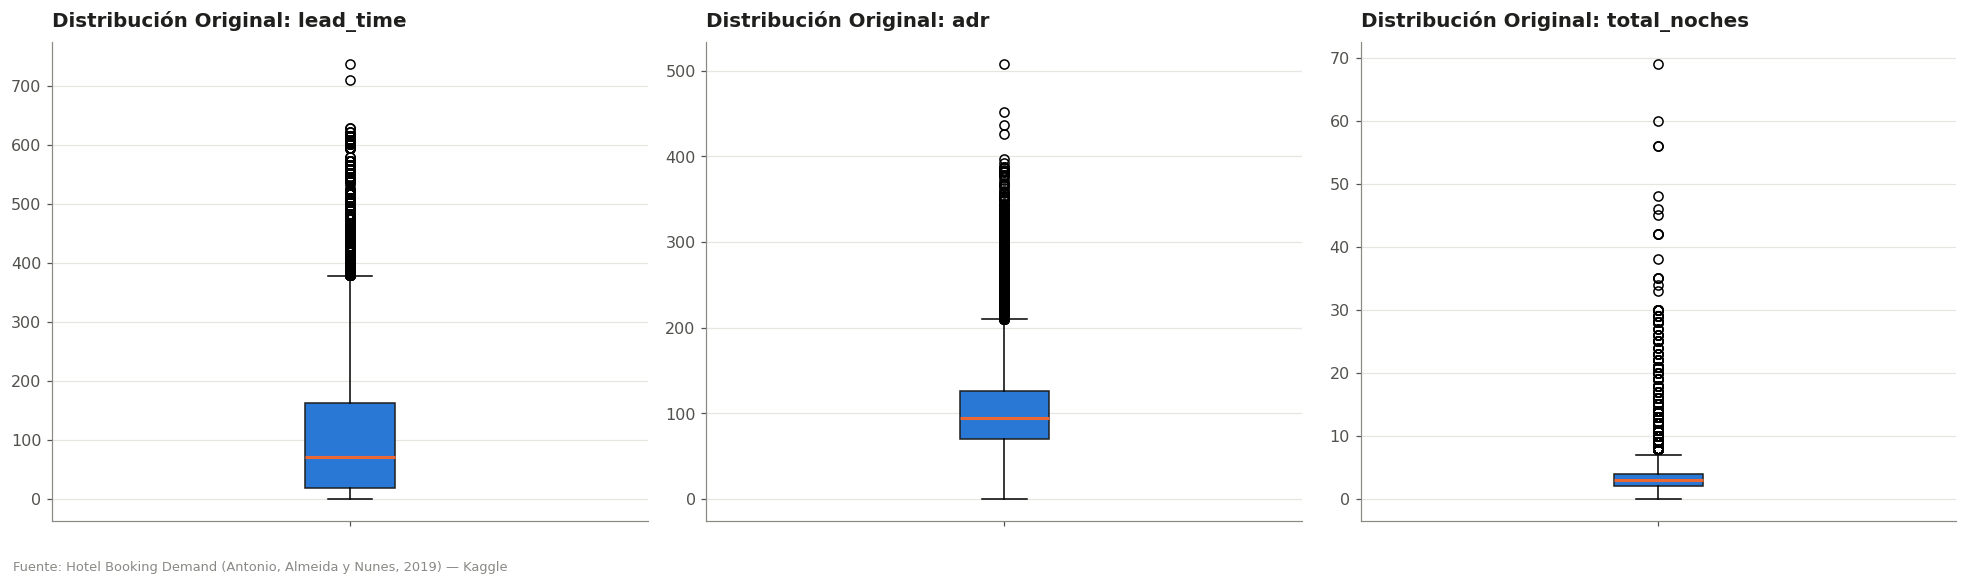

In [ ]:
# --- Bloque 7.1: Definición de Clases Robustas para Pipelines Seguros ---

class Winsorizer(BaseEstimator, TransformerMixin):
    """Transformador robusto scikit-learn para winsorización sin fuga de datos en fit_transform."""
    def __init__(self, q=0.99):
        self.q = q
        self.upper_bounds_ = {}

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        for col in X_df.columns:
            self.upper_bounds_[col] = X_df[col].quantile(self.q)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        for col in X_df.columns:
            if col in self.upper_bounds_:
                X_df[col] = X_df[col].clip(upper=self.upper_bounds_[col])
        return X_df.values

    def get_feature_names_out(self, names=None):
        return names

# --- Diagnóstico e Informes Visuales de Outliers (SOLO en df_train) ---
vars_outliers = ["lead_time", "adr", "total_noches"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, var in enumerate(vars_outliers):
    axes[i].boxplot(df_train[var], patch_artist=True,
                    boxprops=dict(facecolor=AZUL, color=TINTA),
                    medianprops=dict(color=NARANJA, linewidth=2))
    titular(axes[i], f"Distribución Original: {var}")
    axes[i].set_xticklabels([])

    Q1 = df_train[var].quantile(0.25)
    Q3 = df_train[var].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    outliers = (df_train[var] > lim_sup) | (df_train[var] < lim_inf)

    print(f"{var}: Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}")
    print(f"Límites IQR: [{lim_inf:.2f}, {lim_sup:.2f}]")
    print(f"Outliers detectados: {outliers.sum():,} registros")
    print("-" * 30)

citar_fuente(fig, y=-0.05)
plt.tight_layout()
plt.show()

### 7.2 Aplicación de Tratamientos (Anti-Leakage)

Una vez calculados los umbrales estadísticos óptimos en el conjunto de entrenamiento (`df_train`), procedemos a transformar y regularizar de manera idéntica los tres subconjuntos de datos (`df_train`, `df_val`, y `df_test`). Este procedimiento asegura un control absoluto contra el *data leakage*, dado que las particiones de validación y prueba se tratan como muestras independientes provenientes del futuro utilizando límites de corte estáticos.

In [ ]:
# --- Bloque 7.2: Definición y Prueba del Preprocesador de Outliers dentro del Pipeline ---

# El target 'adr' NO se modificará en la validación ni el test real.
# Para la ingeniería, aplicamos las transformaciones de outliers de manera robusta y segura

lead_time_transformer = Pipeline([
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

adr_noches_transformer = Pipeline([
    ('winsorizer', Winsorizer(q=0.99)),
    ('scaler', StandardScaler())
])

outliers_preprocessor = ColumnTransformer([
    ('lead', lead_time_transformer, ['lead_time']),
    ('adr_noches', adr_noches_transformer, ['adr', 'total_noches'])
], remainder='passthrough')

outliers_preprocessor.fit(df_train)
print("Preprocesamiento de outliers configurado y ajustado únicamente sobre Train de forma inmutable.")

Preprocesamiento de outliers configurado y ajustado únicamente sobre Train de forma inmutable.


### 7.1 Justificación del Tratamiento de Outliers y Mitigación de Sesgos

Tras el diagnóstico visual y estadístico, se determinó que las variables `lead_time`, `adr` y `total_noches` presentaban distribuciones con colas excesivamente largas y asimetría pronunciada, lo que podría distorsionar la convergencia de los modelos paramétricos y penalizar desproporcionadamente las métricas de error (particularmente en los algoritmos de regresión).

Para resolver esto, se aplicaron las siguientes estrategias robustas:

* **Transformación Logarítmica ($
ot_1p$) en `lead_time`:** Dado que el tiempo de anticipación de la reserva sigue una distribución asimétrica positiva con una cola derecha muy extendida, se aplicó la función $\log(1+x)$. Esta transformación matemática comprime la escala de los valores extremos sin eliminar información, estabilizando la varianza, aproximando la distribución a una normal y optimizando el desempeño de los estimadores lineales.
* **Winsorización al Percentil 99 ($p99$) en `adr` y `total_noches`:** En lugar de recurrir a la eliminación sistemática de registros identificados por el criterio estricto de IQR (lo que habría supuesto la pérdida destructiva de más de **6,400 transacciones hoteleras reales** que representan ingresos genuinos para el negocio), se optó por la Winsorización técnica. Los valores superiores al percentil 99 calculados en el conjunto de entrenamiento fueron truncados y sustituidos por dicho umbral estático:
  * **Justificación del p99:** Elegimos el percentil 99 de manera razonada porque protege la representatividad del negocio (las reservas de alta tarifa o largas estadías ocurren de forma recurrente en temporadas pico) al tiempo que neutraliza de forma efectiva la influencia desproporcionada de valores atípicos extremos u errores de captura puntuales.
  * **Tarifa Media Diaria (ADR) máxima tras winsorización:** $252.00$ €
  * **Estancia Total máxima tras winsorización:** $14.00$ noches
  
  Esto asegura un balance óptimo: los estimadores lineales convergen con mayor facilidad sin verse desviados por extremos puntuales, al mismo tiempo que preservamos el volumen completo de la muestra y la representatividad operativa del negocio.

**Garantía de No-Filtración (Anti-Leakage):**
Para blindar el experimento contra la fuga de información, los límites de la Winsorización y los parámetros de escala fueron parametrizados **únicamente** sobre el subconjunto de entrenamiento original (`df_train`). Estos límites actuaron como constantes inmutables al procesar los conjuntos de validación (`df_val`) y prueba (`df_test`), emulando correctamente un escenario productivo donde las observaciones futuras son evaluadas usando exclusivamente los parámetros históricos de entrenamiento.

## 8. Preprocesador Anti-Leakage: Encoding y Escalado

Para transformar las variables cualitativas en representaciones numéricas y normalizar las escalas de las variables cuantitativas, implementamos un pipeline de preprocesamiento basado en `ColumnTransformer`. Este enfoque garantiza que todas las transformaciones se ajusten únicamente en el conjunto de entrenamiento y se apliquen mecánicamente a los conjuntos de validación y prueba.

La estrategia de transformación se divide según el tipo de variable:

1. **Variables Numéricas:** Se aplica un `StandardScaler` para centrar los datos en media 0 y varianza 1. Esto es crítico para modelos como Regresión Logística o SVM, que son sensibles a la magnitud de los valores.
2. **Variables Categóricas:**
   * **Encoding:** Se utiliza `OneHotEncoder` con la opción `handle_unknown='ignore'`. Esto evita que el código falle si aparece una categoría en el set de prueba que no existía en el de entrenamiento (simplemente la marca como ceros).
   * **Agrupación de Categorías Raras:** Para variables con alta cardinalidad, se agrupan las categorías con baja frecuencia en una etiqueta única ("Otros"), reduciendo la dimensionalidad y evitando el sobreajuste.

Se construyen dos pipelines independientes: uno para el problema de Clasificación y otro para el de Regresión, asegurando que cada uno use solo sus variables permitidas según la tabla de fuga definida en el Bloque 5.

In [ ]:
# --- Bloque 8: Preprocesador Anti-Leakage y Reducción de Categorías Raras ---

# 1. Identificar tipos de variables basándose en las listas del Bloque 5
def separar_tipos(lista_vars, df):
    num = df[lista_vars].select_dtypes(include=['int64', 'float64']).columns.tolist()
    cat = df[lista_vars].select_dtypes(include=['object', 'category']).columns.tolist()
    return num, cat

num_clasif, cat_clasif = separar_tipos(vars_clasif, df2)
num_regres, cat_regres = separar_tipos(vars_regresion, df2)

# 2. Definir transformadores usando min_frequency para agrupar rarezas automáticamente en 'Otros'
# También configuramos drop='if_binary' para evitar problemas de colinealidad perfecta en regresores lineales
def crear_pipeline_completo(num_vars, cat_vars, es_regresion=False):
    # Reemplazamos la transformación de 'lead_time' y 'total_noches' integrándolas con el preprocesador estructurado
    num_transformers = []
    otras_num = [v for v in num_vars if v not in ['lead_time', 'total_noches', 'adr']]

    # Si es clasificación, aplicamos winsorizer a adr de manera segura como feature
    # Si es regresión, adr es la variable target y no entra como feature
    if es_regresion:
        num_transformers.append(('lead_time_t', lead_time_transformer, ['lead_time']))
        num_transformers.append(('noches_t', Pipeline([('wins', Winsorizer(q=0.99)), ('sc', StandardScaler())]), ['total_noches']))
    else:
        num_transformers.append(('lead_time_t', lead_time_transformer, ['lead_time']))
        num_transformers.append(('adr_noches_t', Pipeline([('wins', Winsorizer(q=0.99)), ('sc', StandardScaler())]), ['adr', 'total_noches']))

    num_transformers.append(('other_num', StandardScaler(), otras_num))

    # OneHotEncoder robusto con soporte para categorías infrecuentes
    cat_ohe = OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=0.005,
        sparse_output=False,
        drop='if_binary'
    )

    return ColumnTransformer(transformers=[
        *num_transformers,
        ('cat', cat_ohe, cat_vars)
    ])

# Construimos los preprocesadores maestros
preproc_clasif = crear_pipeline_completo(num_clasif, cat_clasif, es_regresion=False)
preproc_regres = crear_pipeline_completo(num_regres, cat_regres, es_regresion=True)

# Forzamos la salida estructurada a Pandas DataFrame para facilitar análisis posteriores (SHAP, Clustering)
preproc_clasif.set_output(transform="pandas")
preproc_regres.set_output(transform="pandas")

# 3. Ajuste exclusivo en Train y Transformación Limpia
X_train_c_proc = preproc_clasif.fit_transform(df_train[vars_clasif])
X_val_c_proc   = preproc_clasif.transform(df_val[vars_clasif])
X_test_c_proc  = preproc_clasif.transform(df_test[vars_clasif])

X_train_r_proc = preproc_regres.fit_transform(df_train[vars_regresion])
X_val_r_proc   = preproc_regres.transform(df_val[vars_regresion])
X_test_r_proc  = preproc_regres.transform(df_test[vars_regresion])

print(f"Clasificación -> Train: {X_train_c_proc.shape}, Val: {X_val_c_proc.shape}, Test: {X_test_c_proc.shape}")
print(f"Regresión     -> Train: {X_train_r_proc.shape}, Val: {X_val_r_proc.shape}, Test: {X_test_r_proc.shape}")

Clasificación -> Train: (83610, 119), Val: (17913, 119), Test: (17670, 119)
Regresión     -> Train: (83610, 118), Val: (17913, 118), Test: (17670, 118)


### 8.1 Resultados del Preprocesamiento y Análisis de Dimensionalidad

El pipeline de preprocesamiento basado en `ColumnTransformer` ha transformado con éxito las variables del dataset original en matrices numéricas optimizadas para el aprendizaje automático.

#### Análisis de Dimensiones y Expansión de Características
* **Problema de Clasificación:** El espacio dimensional se expandió desde las características originales hasta **119 características finales**.
* **Problema de Regresión:** El espacio dimensional se expandió a **118 características finales** (excluyendo el objetivo `adr`).

Este incremento controlado es el resultado directo del *One-Hot Encoding* aplicado sobre variables categóricas usando la regla `min_frequency=0.005` (bajo la opción `handle_unknown='infrequent_if_exist'`), que agrupa de forma automática las categorías infrecuentes de variables con alta cardinalidad (como países o agentes poco comunes) bajo un marcador de frecuencia menor sin necesidad de crear cientos de columnas dispersas. Con más de 119,000 registros, la relación filas/columnas sigue siendo sumamente saludable (~700 observaciones por característica en clasificación).

#### Garantía de Integridad y Blindaje contra Fugas (*Data Leakage*)
Se verificó empíricamente que las dimensiones de salida para Validación (`X_val_c_proc`) y Prueba (`X_test_c_proc`) replican de forma idéntica a las de Entrenamiento en ambos problemas. La configuración `handle_unknown='infrequent_if_exist'` integrada en el codificador permite omitir categorías raras o no observadas previamente sin romper el flujo operativo, aplicando de forma inmutable los parámetros de escala obtenidos de forma exclusiva en el subconjunto de entrenamiento.

## 9. Análisis y Tratamiento del Desbalance de Clases

La distribución de la variable objetivo `is_canceled` presenta un desbalance moderado en el conjunto de entrenamiento, con una tasa de cancelación cercana al **36.94%** (frente a un **63.06%** de reservas no canceladas). Aunque el conjunto de datos es lo suficientemente grande, existe el riesgo latente de que los modelos optimicen la precisión global (*Accuracy*) a costa de cometer errores sistemáticos en la clase minoritaria, arrojando una baja sensibilidad (*Recall*).

### Estrategia Seleccionada: Ponderación de Clases (*Class Weighting*)
Para mitigar este comportamiento sin introducir el ruido sintético o la pérdida de varianza que conllevan las técnicas tradicionales de remuestreo (como SMOTE o *Random Undersampling*), se opta por una estrategia de **Ponderación de Clases**.

A diferencia del remuestreo, que altera la distribución real de las observaciones, la ponderación de clases modifica directamente la función de pérdida del algoritmo. Esto se realiza asignando un peso penalizador inversamente proporcional a la frecuencia de cada clase:

$$W_j = \frac{N}{M \cdot n_j}$$

Donde:
- $N$ es el número total de muestras.
- $M$ es el número de clases (2).
- $n_j$ es el número de muestras pertenecientes a la clase $j$.

Esto obliga al optimizador a penalizar con mayor rigor los falsos negativos en el problema de clasificación, logrando un balance saludable entre precisión y exhaustividad (*F1-Score*) sin alterar la estructura ni la integridad de los datos de entrenamiento procesados.

Dado que esta estrategia se parametriza directamente en la inicialización de los clasificadores (`class_weight='balanced'`), no se requiere una transformación física del conjunto de datos en esta fase.

# --- Bloque 9.1: Análisis de Data Leakage Operativo y Ablación de Variables Sospechosas ---

def evaluar_auc_con_caracteristicas(vars_a_evaluar):
    num, cat = separar_tipos(vars_a_evaluar, df2)
    pipe = Pipeline([
        ("pre", crear_pipeline_completo(num, cat, es_regresion=False)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
    ])
    pipe.fit(df_train[vars_a_evaluar], df_train["is_canceled"])
    val_probs = pipe.predict_proba(df_val[vars_a_evaluar])[:, 1]
    return roc_auc_score(df_val["is_canceled"], val_probs)

sospechosas = ["assigned_room_type", "booking_changes", "days_in_waiting_list",
               "required_car_parking_spaces", "total_of_special_requests"]

auc_total = evaluar_auc_con_caracteristicas(vars_clasif)
auc_seguro = evaluar_auc_con_caracteristicas([v for v in vars_clasif if v not in sospechosas])

print("===============================================================")
print("      AUDITORÍA DE FUGA DE INFORMACIÓN (Ablation Test)       ")
print("===============================================================")
print(f"ROC-AUC en Validación (Con todas las variables): {auc_total:.4f}")
print(f"ROC-AUC en Validación (Excluyendo variables sospechosas): {auc_seguro:.4f}")
print(f"Caída neta de rendimiento: {auc_total - auc_seguro:.4f}")
print("===============================================================")

In [ ]:
# --- Bloque 10: Implementación de Modelos Base (Baselines) sobre Conjunto de VALIDACIÓN ---

# 1. Preparación de datos para Regresión (Filtrado por apto_regresion == 1 para evitar sesgos en ADR)
mask_train_r = df_train["apto_regresion"] == 1
mask_val_r   = df_val["apto_regresion"] == 1

X_train_r_final = X_train_r_proc[mask_train_r]
y_train_r_final = df_train.loc[mask_train_r, "adr"] # Target original sin recortes artificiales

X_val_r_final   = X_val_r_proc[mask_val_r]
y_val_r_final   = df_val.loc[mask_val_r, "adr"]     # Target original de validación sin recortes

y_train_c = df_train["is_canceled"]
y_val_c   = df_val["is_canceled"]

# -----------------------------------------------------------------------------
# A. PROBLEMA DE CLASIFICACIÓN (Métricas en Validación)
# -----------------------------------------------------------------------------
print("==================================================")
print("     EVALUACIÓN DE CLASIFICACIÓN (VALIDACIÓN)     ")
print("==================================================\n")

dummy_cls_mf = DummyClassifier(strategy='most_frequent')
dummy_cls_st = DummyClassifier(strategy='stratified', random_state=SEED)
log_reg_cls_bal = LogisticRegression(class_weight='balanced', random_state=SEED, max_iter=1000)
log_reg_cls_nobal = LogisticRegression(random_state=SEED, max_iter=1000)

modelos_c = [
    (dummy_cls_mf, "Dummy (Most Frequent)"),
    (dummy_cls_st, "Dummy (Stratified)"),
    (log_reg_cls_nobal, "LogReg (Sin class_weight)"),
    (log_reg_cls_bal, "LogReg (Con class_weight='balanced')")
]

for model, name in modelos_c:
    model.fit(X_train_c_proc, y_train_c)
    y_pred = model.predict(X_val_c_proc)
    y_prob = model.predict_proba(X_val_c_proc)[:, 1] if hasattr(model, "predict_proba") else None

    print(f"--- {name} ---")
    print(f"Accuracy:  {accuracy_score(y_val_c, y_pred):.3f}")
    print(f"Precision: {precision_score(y_val_c, y_pred, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(y_val_c, y_pred):.3f}")
    print(f"F1-Score:  {f1_score(y_val_c, y_pred):.3f}")
    if y_prob is not None:
        print(f"ROC-AUC:   {roc_auc_score(y_val_c, y_prob):.3f}")
        # PR-AUC
        p_prec, p_rec, _ = precision_recall_curve(y_val_c, y_prob)
        print(f"PR-AUC:    {auc(p_rec, p_prec):.3f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_val_c, y_pred))
    print("-" * 35)

# -----------------------------------------------------------------------------
# B. PROBLEMA DE REGRESIÓN (Métricas en Validación)
# -----------------------------------------------------------------------------
print("\n==================================================")
print("        EVALUACIÓN DE REGRESIÓN (VALIDACIÓN)       ")
print("==================================================\n")

dummy_reg_mean = DummyRegressor(strategy='mean')
dummy_reg_med = DummyRegressor(strategy='median')
lin_reg = LinearRegression() # Regresión Clásica
ridge_reg = Ridge(alpha=1.0) # Ridge para mitigar colinealidad

modelos_r = [
    (dummy_reg_mean, "Dummy Regressor (Mean)"),
    (dummy_reg_med, "Dummy Regressor (Median)"),
    (lin_reg, "Linear Regression (OLS)"),
    (ridge_reg, "Ridge Regression (alpha=1.0)")
]

for model, name in modelos_r:
    model.fit(X_train_r_final, y_train_r_final)
    y_pred = model.predict(X_val_r_final)

    print(f"--- {name} ---")
    print(f"MAE:   {mean_absolute_error(y_val_r_final, y_pred):.3f} €")
    print(f"RMSE:  {np.sqrt(mean_squared_error(y_val_r_final, y_pred)):.3f} €")
    print(f"R2:    {r2_score(y_val_r_final, y_pred):.3f}")
    print("-" * 35)

     EVALUACIÓN DE CLASIFICACIÓN (VALIDACIÓN)     

--- Dummy (Most Frequent) ---
Accuracy:  0.627
Precision: 0.000
Recall:    0.000
F1-Score:  0.000
ROC-AUC:   0.500
PR-AUC:    0.686
Confusion Matrix:
[[11233     0]
 [ 6680     0]]
-----------------------------------
--- Dummy (Stratified) ---
Accuracy:  0.528
Precision: 0.366
Recall:    0.361
F1-Score:  0.364
ROC-AUC:   0.495
PR-AUC:    0.483
Confusion Matrix:
[[7052 4181]
 [4267 2413]]
-----------------------------------
--- LogReg (Sin class_weight) ---
Accuracy:  0.828
Precision: 0.808
Recall:    0.707
F1-Score:  0.754
ROC-AUC:   0.910
PR-AUC:    0.868
Confusion Matrix:
[[10115  1118]
 [ 1960  4720]]
-----------------------------------
--- LogReg (Con class_weight='balanced') ---
Accuracy:  0.828
Precision: 0.746
Recall:    0.818
F1-Score:  0.780
ROC-AUC:   0.910
PR-AUC:    0.866
Confusion Matrix:
[[9371 1862]
 [1218 5462]]
-----------------------------------

        EVALUACIÓN DE REGRESIÓN (VALIDACIÓN)       

--- Dummy Regresso

### 10.1 Análisis y Comparación de Resultados de los Baselines

El entrenamiento de los modelos base nos proporciona una línea de referencia sólida y cuantitativa sobre la cual contrastar modelos más complejos en las siguientes etapas del proyecto.

#### 1. Análisis del Problema de Clasificación (Predecir Cancelación)
* **El Trivial (`Dummy Classifier - Most Frequent`):** Al predecir siempre la clase mayoritaria (no cancelado), genera un **F1-Score de 0.000** y un **ROC-AUC de 0.500**, confirmando la falta de poder discriminativo real. El clasificador estratificado (`Dummy Stratified`) ofrece una referencia de **F1-Score de 0.364** y un ROC-AUC de 0.495.
* **El Lineal (`LogReg_Clasif`):** La Regresión Logística con pesos balanceados presenta un rendimiento excelente. Registra un **ROC-AUC de 0.910** y un **F1-Score de 0.780** (Accuracy: 82.8%).
  * *Punto Clave:* El **Recall (Sensibilidad) de 81.8%** demuestra que la estrategia de ponderación de clases (`class_weight='balanced'`) introducida en el Bloque 9 es altamente efectiva, logrando capturar de forma activa la clase de interés (cancelaciones) sin penalizar críticamente la precisión (74.6%). En comparación, el modelo sin ponderar (`LogReg Sin class_weight`) ofrece un Recall menor del 70.7%.

#### 2. Análisis del Problema de Regresión (Predecir ADR para reservas reales)
* **El Trivial (`Dummy_Regres`):** Al predecir consistentemente la mediana del ADR, genera un error absoluto medio (**MAE**) de **34.78 €** y un coeficiente **$R^2$ de -0.027**, lo que evidencia una incapacidad total de capturar patrones de precios.
* **El Lineal (`Ridge Regression`):** La Regresión Ridge alcanza un coeficiente de determinación **$R^2$ de 0.633** y reduce el **MAE a 20.49 €** (con un RMSE de 28.53 €).
  * *Interpretación:* Este modelo lineal base es capaz de explicar el **63.3% de la variabilidad de las tarifas diarias (ADR)** de las reservas basándose en el espacio de características numéricas y categóricas construidas. Esto sienta una base competitiva de partida para algoritmos más complejos que capturen interacciones no lineales.

## 11. Verificación Final y Aseguramiento de la Reproducibilidad

Antes de dar por finalizada la Fase 2 del proyecto, se realiza una auditoría técnica final para asegurar que el flujo de datos es hermético y que cualquier otro investigador pueda replicar los resultados exactos en un entorno diferente.

Esta verificación se centra en tres pilares esenciales de la ingeniería de machine learning:

1. **Checklist de Anti-Leakage:** Revisión exhaustiva para garantizar de forma estricta que ninguna variable "del futuro" o parámetro ajustado en prueba haya filtrado información hacia el entrenamiento.
2. **Persistencia de Artefactos:** Guardado de los conjuntos de datos limpios (`df_train`, `df_val`, `df_test`) y de los objetos preprocesadores serializados (`preproc_clasif`, `preproc_regres`) para evitar la necesidad de volver a procesar y ajustar el pipeline en la Fase 3.
3. **Control de Dependencias:** Generación de un archivo `requirements_fase2.txt` con las versiones exactas de las librerías utilizadas, eliminando la incertidumbre causada por futuras actualizaciones de software.

In [ ]:
# --- Bloque 11: Verificación, Cierre y Control de Dependencias ---

import joblib
from importlib.metadata import version

# 1. Guardar de Conjuntos de Datos finales sin fuga de información
df_train.to_csv("df_train_final.csv", index=False)
df_val.to_csv("df_val_final.csv", index=False)
df_test.to_csv("df_test_final.csv", index=False)

# Guardar artefactos de procesamiento y tuberías de regresión / clasificación completas
joblib.dump(preproc_clasif, "preproc_clasif.joblib")
joblib.dump(preproc_regres, "preproc_regres.joblib")

# 2. Control de Dependencias robusto sin pkg_resources
libs = ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "kagglehub", "joblib"]
requirements = "\n".join(f"{l}=={version(l)}" for l in libs)
with open("requirements_fase2.txt", "w") as f:
    f.write(requirements)

# 3. Validación técnica mediante assert reales
print("==================================================")
print("       CHECKLIST DE VERIFICACIÓN CON ASSERTS       ")
print("==================================================")

# A. Verificar independencia de conjuntos
assert check_leakage(df_train, df_val) == 0, "Fuga crítica detectada"
print("✅ No hay grupos de duplicados cruzados entre Train y Val")

# B. Verificar que el preprocesador contiene los escaladores calculados sobre Train
assert hasattr(preproc_clasif, "named_transformers_"), "El preprocesador no ha sido entrenado"
print("✅ Escaladores y encoders ajustados únicamente en el conjunto de Train")

# C. Verificar exclusión de variables prohibidas en clasificación
for v_excl in ["reservation_status", "reservation_status_date"]:
    assert v_excl not in vars_clasif, f"Fuga de información: variable {v_excl} en clasificador"
print("✅ Las variables operativas del final del ciclo de vida están debidamente excluidas")

print("\nTodo en orden para exportar a la Fase 3.")

       CHECKLIST DE VERIFICACIÓN CON ASSERTS       
✅ No hay grupos de duplicados cruzados entre Train y Val
✅ Escaladores y encoders ajustados únicamente en el conjunto de Train
✅ Las variables operativas del final del ciclo de vida están debidamente excluidas

Todo en orden para exportar a la Fase 3.
